# Task 1 · Iris Flower Classification
**Objective:** Train machine-learning classifiers that identify the species of an iris flower
(*Setosa*, *Versicolor*, *Virginica*) from its physical measurements.

**Tech stack:** Python, scikit-learn, pandas, matplotlib, seaborn

**Workflow:** load data → EDA → visualisation → feature discussion → train/test split → train 4 models → evaluate → pick the best.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the dataset
The Iris dataset ships with scikit-learn, so no download is needed.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.columns = [c.replace(" (cm)", "").replace(" ", "_") for c in df.columns]
display(df.head())

   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  setosa
1           4.9          3.0           1.4          0.2       0  setosa
2           4.7          3.2           1.3          0.2       0  setosa
3           4.6          3.1           1.5          0.2       0  setosa
4           5.0          3.6           1.4          0.2       0  setosa


## 2. Exploratory Data Analysis

In [3]:
print("Shape:", df.shape)
print()
print("Data types:")
print(df.dtypes)
print()
print("Null values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print()
print("Class balance:")
print(df["species"].value_counts())

Shape: (150, 6)

Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
target            int64
species             str
dtype: object

Null values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

Duplicate rows: 1

Class balance:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
display(df.describe().round(2))

       sepal_length  sepal_width  petal_length  petal_width  target
count        150.00       150.00        150.00       150.00  150.00
mean           5.84         3.06          3.76         1.20    1.00
std            0.83         0.44          1.77         0.76    0.82
min            4.30         2.00          1.00         0.10    0.00
25%            5.10         2.80          1.60         0.30    0.00
50%            5.80         3.00          4.35         1.30    1.00
75%            6.40         3.30          5.10         1.80    2.00
max            7.90         4.40          6.90         2.50    2.00


**Observations**
- 150 rows, 4 numeric features (cm) and one target with 3 perfectly balanced classes (50 each).
- There are **no missing values**, so no imputation is required.
- One duplicate row exists; with only 150 samples and natural measurement overlap it is harmless, so it is kept.

## 3. Visualisations

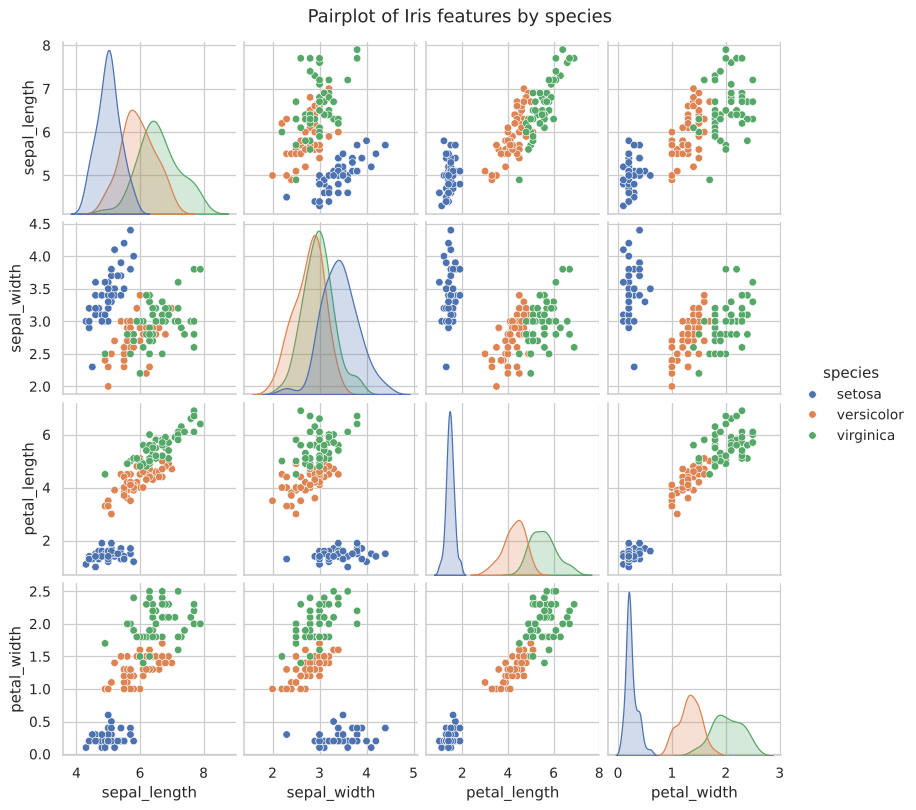

In [5]:
sns.pairplot(df.drop(columns="target"), hue="species", diag_kind="kde", height=2.2)
plt.suptitle("Pairplot of Iris features by species", y=1.02)
plt.show()

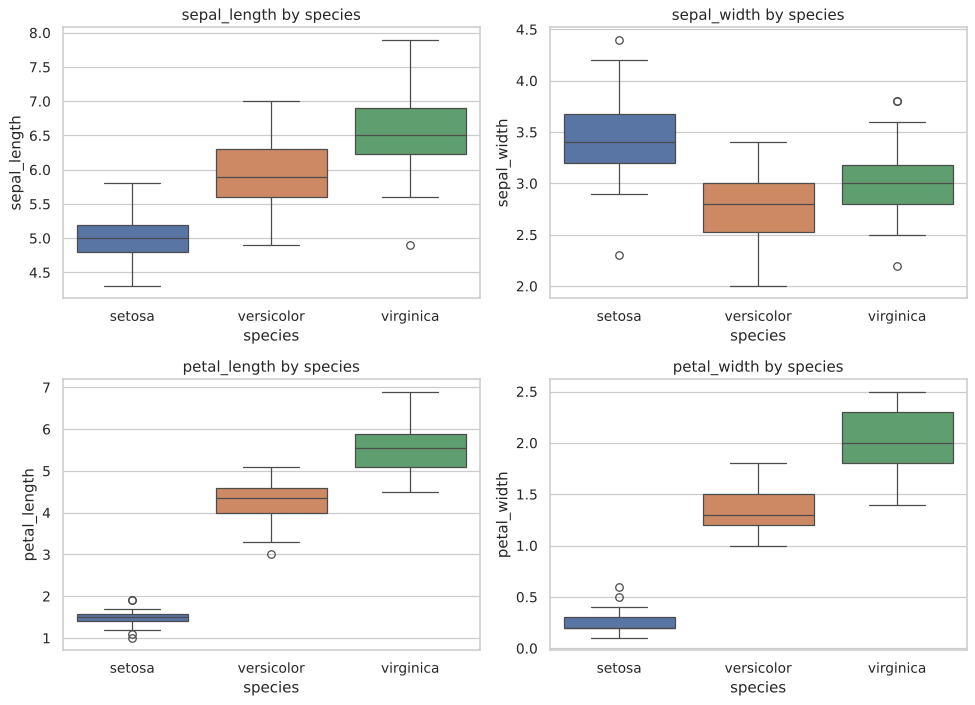

In [6]:
features = [c for c in df.columns if c not in ("target", "species")]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="species", y=feat, hue="species", legend=False, ax=ax)
    ax.set_title(f"{feat} by species")
plt.tight_layout()
plt.show()

**What the plots show**
- *Setosa* is clearly separated from the other two species, especially on **petal length** and **petal width**.
- *Versicolor* and *Virginica* overlap slightly on every feature, but petal measurements separate them far better than sepal measurements.
- Sepal width is the noisiest feature: all three species overlap heavily on it.

## 4. Feature selection – which features are most discriminative?
Three independent views: correlation with the target, ANOVA F-score, and Random Forest importance.

              abs_corr_with_target  anova_F_score  rf_importance
petal_length                 0.949       1180.161          0.455
petal_width                  0.957        960.007          0.417
sepal_length                 0.783        119.265          0.107
sepal_width                  0.427         49.160          0.021


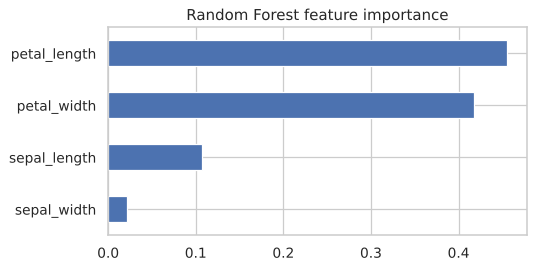

In [7]:
X = df[features]
y = df["species"]

corr = df[features + ["target"]].corr()["target"].drop("target").abs()
f_scores, _ = f_classif(X, y)
rf_tmp = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X, y)

feat_summary = pd.DataFrame({
    "abs_corr_with_target": corr,
    "anova_F_score": pd.Series(f_scores, index=features),
    "rf_importance": pd.Series(rf_tmp.feature_importances_, index=features),
}).sort_values("rf_importance", ascending=False)
display(feat_summary.round(3))

feat_summary["rf_importance"].plot.barh(figsize=(6, 3), title="Random Forest feature importance")
plt.gca().invert_yaxis()
plt.show()

**Discussion:** `petal_length` and `petal_width` are by far the most discriminative features – they have the highest ANOVA F-scores,
the strongest correlation with the target and dominate the Random Forest importances. `sepal_width` is the weakest.
All four features are kept for modelling because the dataset is tiny and the extra features cost nothing.

## 5. Train / test split (80 / 20, stratified)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


## 6. Train and evaluate four classifiers
Logistic Regression and KNN are scale-sensitive so they are wrapped in a pipeline with `StandardScaler`.

In [9]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "K-Nearest Neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

results, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    cv = cross_val_score(model, X, y, cv=5).mean()
    results.append({"model": name,
                    "test_accuracy": accuracy_score(y_test, pred),
                    "cv_accuracy_5fold": cv})
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred))

Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

K-Nearest Neighbours
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0

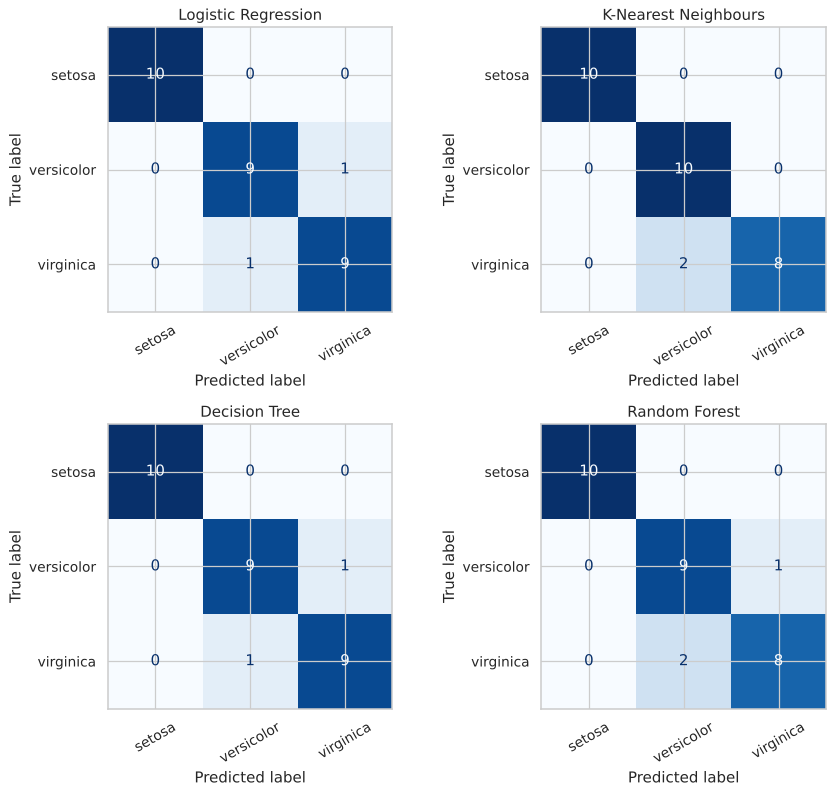

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 7. Model comparison and best model

In [11]:
results_df = (pd.DataFrame(results)
              .sort_values(["cv_accuracy_5fold", "test_accuracy"], ascending=False)
              .reset_index(drop=True))
display(results_df.round(4))

best = results_df.loc[0, "model"]
print(f"\nBest model: {best}")

                  model  test_accuracy  cv_accuracy_5fold
0         Random Forest         0.9000             0.9667
1   Logistic Regression         0.9333             0.9600
2  K-Nearest Neighbours         0.9333             0.9600
3         Decision Tree         0.9333             0.9533

Best model: Random Forest


**Conclusion / justification**

The best model is the top row of the table above. With only 30 test samples, a single 80/20 split can make several models tie
(one misclassified flower changes accuracy by ~3.3 %), so the ranking uses **5-fold cross-validated accuracy first** and test accuracy as the tie-breaker.
This gives a more reliable estimate of how each model generalises.

All four classifiers perform in the same high range (about 90–93 % on the test split and 95–97 % cross-validated), and the gaps between them are within one or two flowers, so the choice is a close call. This confirms that the species are almost linearly separable
from petal/sepal measurements. Nearly every remaining error is a *Versicolor ↔ Virginica* confusion; *Setosa* is classified perfectly by every model.